# Steam Game Popularity Predictor: Exploratory Data Analysis (EDA)

**Course**: Programming for AI -- Project 1 (ETL + EDA)  
**Author**: Student (EDA Specialist)  
**Database**: SQLite (`data/steam.db`)  
**Objective**: Analyze how pre-launch attributes (pricing, multi-label genres, platform support, release timing) relate to commercial popularity tiers on Steam.

---
### Viva Defense Guide
This notebook is structured to defend each analytical finding clearly:
1. **Summary Statistics & Distributions**: Why variables are skewed and why log transforms are needed.
2. **Missing Values & Outlier Detection**: How the ETL handled cleanups and what the IQR method reveals.
3. **Genre Performance**: How multi-label categories are exploded and why low-sample categories must be flagged.
4. **Price Band Dynamics**: Why the relation between price and sales is non-linear.
5. **Free vs. Paid Comparison**: The commercial scale advantage of the free-to-play model.
6. **Platform Support**: Why multi-OS support (Windows, Mac, Linux) correlates with commercial success.
7. **Yearly Trends**: The explosion of catalog volume and market saturation.
8. **Correlation & Leakage Quarantine**: Identifying post-launch outcome leakage to protect future ML models.
9. **Target Class Imbalance**: Why Macro-F1 and stratified sampling are mandatory for Project 2 and 3.


## 1. Setup & Data Loading
We load the validated data directly from the SQLite database created by our teammate's ETL pipeline.
We operate in **read-only mode** -- no data is written to the database.


In [1]:
import sys
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is on sys.path so 'eda' module can be imported from notebooks/
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
if str(Path(".").resolve()) not in sys.path:
    sys.path.insert(0, str(Path(".").resolve()))

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 100

# Database path (relative to project root or current dir)
db_path = Path("..") / "data" / "steam.db"
if not db_path.exists():
    db_path = Path("data") / "steam.db"

db_url = f"sqlite:///{db_path}"
print(f"Connecting to database: {db_path.resolve()}")

# Load data into pandas
con = sqlite3.connect(db_path)
df_games = pd.read_sql_query("SELECT * FROM games", con)
df_genres = pd.read_sql_query(
    "SELECT gg.game_appid AS appid, g.name AS genre "
    "FROM game_genres gg JOIN genres g ON gg.genre_id = g.id",
    con
)
con.close()

print(f"Loaded games table: {df_games.shape[0]} rows, {df_games.shape[1]} columns")
print(f"Loaded genre mappings: {df_genres.shape[0]} rows across {df_genres['genre'].nunique()} distinct genres")
df_games.head(3)


Connecting to database: C:\Users\Hp\Documents\GitHub\steam-popularity-predictor\data\steam.db
Loaded games table: 1500 rows, 31 columns
Loaded genre mappings: 4243 rows across 23 distinct genres


,appid,name,release_date,release_year,release_month,english,developer,publisher,price,is_free,...,popularity_tier,positive_ratings,negative_ratings,review_score,average_playtime,median_playtime,platforms,categories,genres,steamspy_tags
0,1510,Uplink,2006-08-23,2006,8,1,Introversion Software,Introversion Software,6.99,0,...,High,1602,152,0.9133,65,77,windows;mac;linux,Single-player,Indie;Strategy,Hacking;Indie;Strategy
1,2330,QUAKE II Mission Pack: The Reckoning,2007-08-03,2007,8,1,Xatrix Entertainment,id Software,2.49,0,...,High,65,12,0.8442,32,32,windows,Single-player;Multi-player;Steam Cloud,Action,Action;FPS;Classic
2,2800,X2: The Threat,2006-07-21,2006,7,1,Egosoft,Egosoft,4.99,0,...,High,212,50,0.8092,732,732,windows,Single-player;Captions available;Steam Cloud,Strategy,Space;Strategy;Simulation


## 2. Summary Statistics & Skewed Distributions
We inspect the primary numeric features: Price, Estimated Owners, Achievements, and Playtime.
Because commercial hit products follow a power-law distribution, many of these variables exhibit extreme right-tail skewness.


In [2]:
from eda.tables import summary_statistics

stats_df, stats_insight = summary_statistics(df_games)
print("Insight:", stats_insight)
stats_df


Insight: The median game price is $3.99 and the mean estimated owners is 106,620. High standard deviations across most fields indicate a highly diverse dataset.


,field,count,mean,std,min,Q1,median,Q3,max,is_post_launch
0,price,1500.0,6.0317,7.9917,0.0,1.6900,3.9900,7.1900,209.99,False
1,required_age,1500.0,0.2927,2.1905,0.0,0.0000,0.0000,0.0000,18.00,False
2,achievements,1500.0,45.1800,324.0433,0.0,0.0000,7.0000,23.0000,5000.00,False
3,owners_mid,1500.0,106620.0000,420127.8145,10000.0,10000.0000,10000.0000,35000.0000,7500000.00,False
4,positive_ratings,1500.0,650.5020,4581.2781,0.0,6.0000,24.5000,122.0000,145035.00,True
5,negative_ratings,1500.0,150.3213,1794.0168,0.0,2.0000,9.0000,40.0000,66603.00,True
6,review_score,1500.0,0.7152,0.2402,0.0,0.5884,0.7664,0.9029,1.00,True
7,average_playtime,1500.0,103.0800,681.9251,0.0,0.0000,0.0000,0.0000,15906.00,True
8,median_playtime,1500.0,75.9180,284.5959,0.0,0.0000,0.0000,0.0000,5934.00,True


### Visualization: Histograms and Boxplots with Log Scaling
Notice the heavy skew in `price` and `owners_mid`. When variables span several orders of magnitude, linear histograms compress 95% of data into the first bin.
Applying a log transformation ($\log_{10}(x + 1)$) spreads the distribution so patterns become visible.


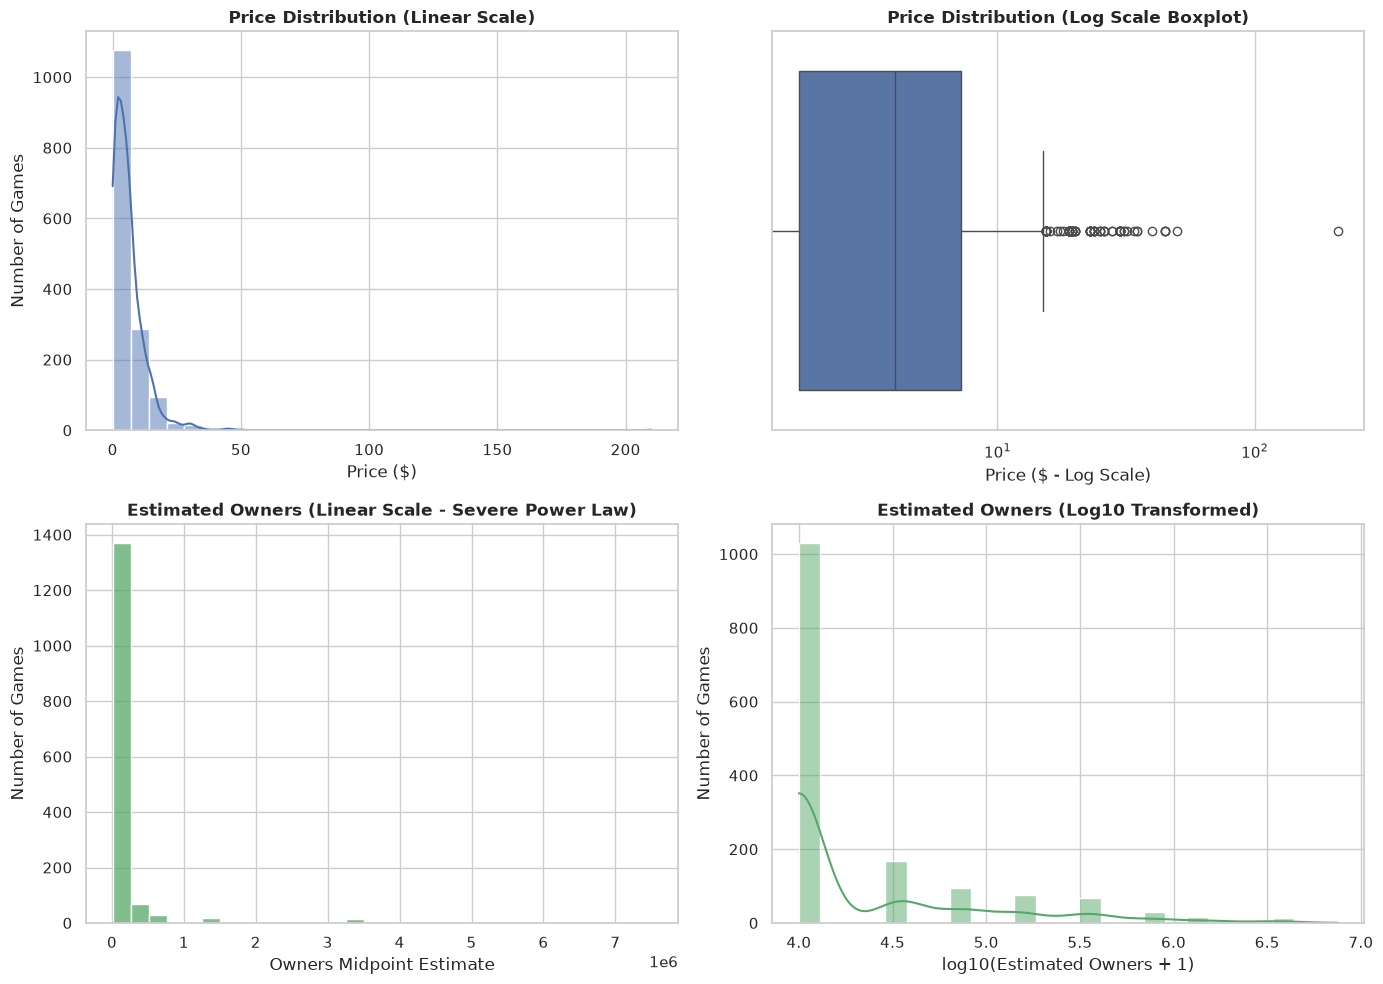

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Price - Linear Histogram
sns.histplot(df_games["price"], bins=30, ax=axes[0, 0], color="#4c72b0", kde=True)
axes[0, 0].set_title("Price Distribution (Linear Scale)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Price ($)")
axes[0, 0].set_ylabel("Number of Games")

# 2. Price - Log-scale Boxplot
sns.boxplot(x=df_games["price"], ax=axes[0, 1], color="#4c72b0")
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("Price Distribution (Log Scale Boxplot)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Price ($ - Log Scale)")

# 3. Estimated Owners - Linear Histogram
sns.histplot(df_games["owners_mid"], bins=30, ax=axes[1, 0], color="#55a868", kde=False)
axes[1, 0].set_title("Estimated Owners (Linear Scale - Severe Power Law)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Owners Midpoint Estimate")
axes[1, 0].set_ylabel("Number of Games")

# 4. Estimated Owners - Log Scale Histogram
log_owners = np.log10(df_games["owners_mid"] + 1)
sns.histplot(log_owners, bins=25, ax=axes[1, 1], color="#55a868", kde=True)
axes[1, 1].set_title("Estimated Owners (Log10 Transformed)", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("log10(Estimated Owners + 1)")
axes[1, 1].set_ylabel("Number of Games")

plt.tight_layout()
plt.show()


## 3. Missing Values & Outlier Analysis (IQR Method)
- **Missing Values**: The ETL layer resolved missing numbers to standard defaults ($0.0$ for price, $0$ for ratings and playtimes).
- **Outliers**: Identified using Tukey's Interquartile Range method:
  $$\text{Lower Fence} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Upper Fence} = Q_3 + 1.5 \times \text{IQR}$$
  Values beyond these fences represent statistically anomalous data points.


In [4]:
from eda.tables import missing_and_outliers

outliers_df, outliers_insight = missing_and_outliers(df_games)
print("Insight:", outliers_insight)
outliers_df


Insight: The dataset has 0 missing numeric values (ETL imputed defaults). 1723 IQR-based outliers detected in total; average_playtime has the most (346, 23.07%) driven by right-tail blockbuster values.


,field,missing_count,missing_pct,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count,outlier_pct,is_post_launch
0,price,0,0.0,1.6900,7.1900,5.5000,-6.5600,15.4400,93,6.20,False
1,required_age,0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,27,1.80,False
2,achievements,0,0.0,0.0000,23.0000,23.0000,-34.5000,57.5000,98,6.53,False
3,owners_mid,0,0.0,10000.0000,35000.0000,25000.0000,-27500.0000,72500.0000,302,20.13,False
4,positive_ratings,0,0.0,6.0000,122.0000,116.0000,-168.0000,296.0000,247,16.47,True
5,negative_ratings,0,0.0,2.0000,40.0000,38.0000,-55.0000,97.0000,216,14.40,True
6,review_score,0,0.0,0.5885,0.9029,0.3144,0.1168,1.3745,48,3.20,True
7,average_playtime,0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,346,23.07,True
8,median_playtime,0,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,346,23.07,True


## 4. Genre Performance Analysis
Steam games are multi-label: a single game can be simultaneously tagged as `Action`, `Indie`, and `RPG`.
To analyze genre popularity without losing multi-label associations, we join with the exploded `game_genres` relation.
Genres with fewer than 10 titles are explicitly flagged as `low_sample` to prevent misleading conclusions in a viva.


In [5]:
from eda.tables import genre_performance

genre_df, genre_insight = genre_performance(df_games, df_genres)
print("Insight:", genre_insight)
genre_df.head(10)


Insight: Utilities leads with avg 290,000 estimated owners across 7 games. 23 genres analysed; 7 have fewer than 10 games (flagged as low-sample).


,genre,game_count,avg_owners,avg_review_score_post_launch,avg_price,low_sample_flag
0,Utilities,7,290000.0000,0.7031,0.8257,True
1,Massively Multiplayer,42,265595.2381,0.5977,5.0881,False
2,Free to Play,87,172413.7931,0.6765,0.1400,False
3,RPG,257,166634.2412,0.7222,6.8577,False
4,Web Publishing,1,150000.0000,0.9056,18.9900,True
5,Simulation,295,125661.0169,0.6496,6.5505,False
6,Strategy,283,124452.2968,0.6938,6.8347,False
7,Action,679,119609.7202,0.7163,5.9330,False
8,Sports,70,105071.4286,0.6566,7.2141,False
9,Adventure,519,101560.6936,0.7155,6.0939,False


### Visualization: Average Owners and Game Count by Genre


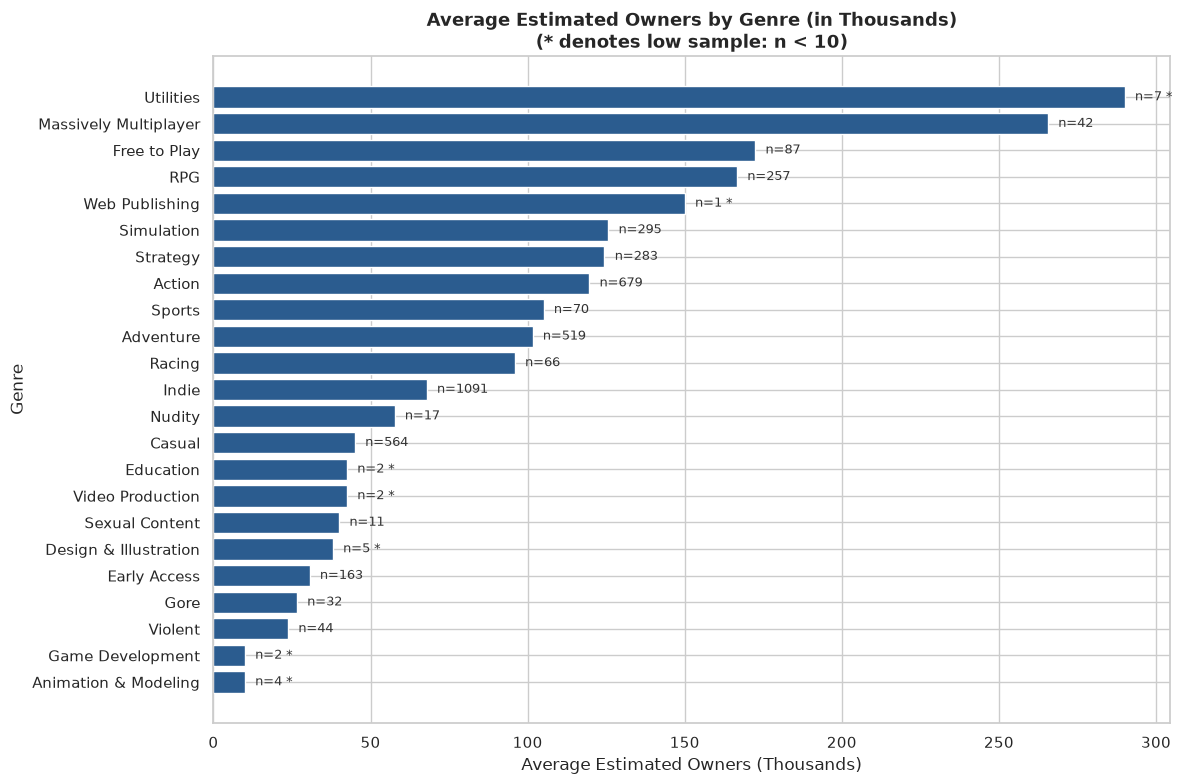

In [6]:
# Sort genres by average owners
plot_genre = genre_df.sort_values("avg_owners", ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(plot_genre["genre"], plot_genre["avg_owners"] / 1000, color="#2b5c8f")

# Annotate sample count on each bar
for bar, count, is_low in zip(bars, plot_genre["game_count"], plot_genre["low_sample_flag"]):
    width = bar.get_width()
    label = f" n={count}" + (" *" if is_low else "")
    ax.text(width + 2, bar.get_y() + bar.get_height() / 2, label,
            va="center", ha="left", fontsize=9, color="#333333")

ax.set_title("Average Estimated Owners by Genre (in Thousands)\n(* denotes low sample: n < 10)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Average Estimated Owners (Thousands)")
ax.set_ylabel("Genre")
plt.tight_layout()
plt.show()


## 5. Price Band Analysis
We partition game prices into six standard market bands:
- **Free**: $0.00
- **<$5**: $0.01 to $4.99
- **$5-10**: $5.00 to $9.99
- **$10-20**: $10.00 to $19.99
- **$20-40**: $20.00 to $39.99
- **$40+**: $40.00 and above

We evaluate how price band relates to review scores, average owners, and popularity tier shares.


In [7]:
from eda.tables import price_band_analysis

price_band_df, price_band_insight = price_band_analysis(df_games)
print("Insight:", price_band_insight)
price_band_df


Insight: The $20-40 band has the highest avg review score (0.782). Free games show 15.22% High-tier representation. Premium games tend toward higher review scores but smaller audiences.


,price_band,game_count,avg_review_score_post_launch,avg_owners,pct_Low,pct_Medium,pct_High
0,Free,138,0.7104,154529.0,44.20,40.58,15.22
1,<$5,715,0.6832,44154.0,76.36,20.56,3.08
2,$5-10,373,0.7462,99330.0,68.90,21.18,9.92
3,$10-20,233,0.7558,192575.0,63.09,20.60,16.31
4,$20-40,36,0.7820,478750.0,44.44,27.78,27.78
5,$40+,5,0.7526,1576000.0,60.00,0.00,40.00


### Visualization: Grouped Bar Chart of Tier Mix Across Price Bands


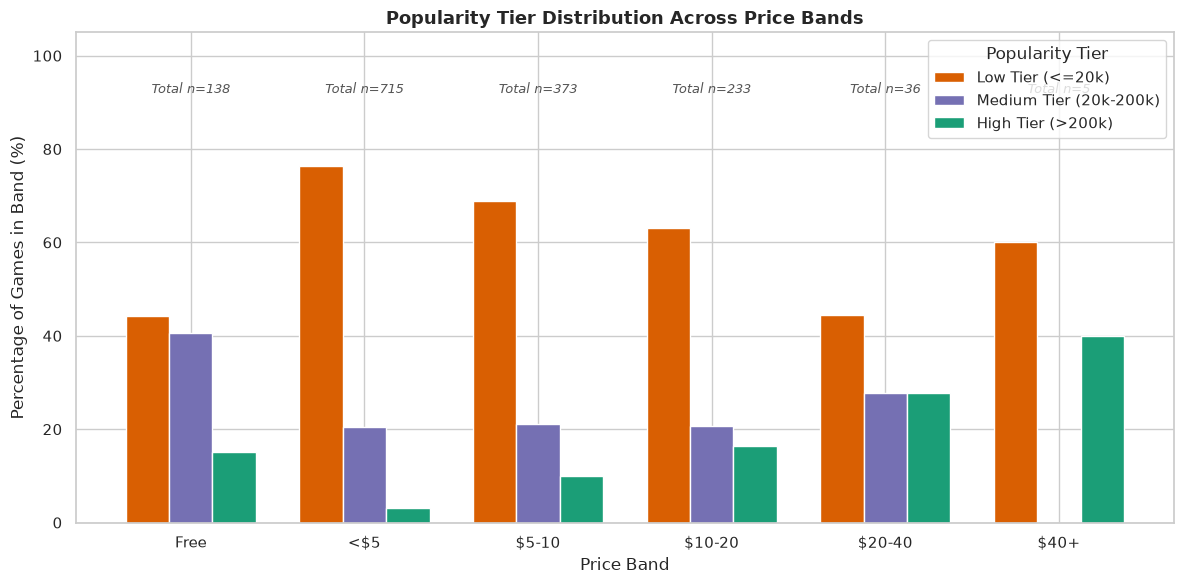

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(price_band_df))
width = 0.25

rects1 = ax.bar(x - width, price_band_df["pct_Low"], width, label="Low Tier (<=20k)", color="#d95f02")
rects2 = ax.bar(x, price_band_df["pct_Medium"], width, label="Medium Tier (20k-200k)", color="#7570b3")
rects3 = ax.bar(x + width, price_band_df["pct_High"], width, label="High Tier (>200k)", color="#1b9e77")

ax.set_title("Popularity Tier Distribution Across Price Bands", fontsize=13, fontweight="bold")
ax.set_xlabel("Price Band")
ax.set_ylabel("Percentage of Games in Band (%)")
ax.set_xticks(x)
ax.set_xticklabels(price_band_df["price_band"])
ax.legend(title="Popularity Tier", frameon=True)

# Add game count annotations above each band cluster
for i, count in enumerate(price_band_df["game_count"]):
    ax.text(i, 92, f"Total n={count}", ha="center", fontsize=9, style="italic", color="#555")

ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()


## 6. Free vs. Paid Games Comparison
Evaluating whether the free-to-play model offers a quantifiable scale advantage over upfront paid titles.


In [9]:
from eda.tables import free_vs_paid

fvp_df, fvp_insight = free_vs_paid(df_games)
print("Insight:", fvp_insight)
fvp_df


Insight: Free-to-play games (138 titles) average 154,529 estimated owners vs 101,766 for paid (1.5x difference), demonstrating the scale advantage of the F2P model.


,category,game_count,pct_of_total,avg_owners,median_owners,avg_review_score_post_launch,avg_playtime_post_launch,pct_Low,pct_Medium,pct_High
0,Free,138,9.2,154529.0,35000.0,0.7104,207.0,44.20,40.58,15.22
1,Paid,1362,90.8,101766.0,10000.0,0.7157,93.0,71.15,20.85,8.00


## 7. Platform Support Comparison
We compare games supporting Windows, Mac, and Linux.
All games in the sample support Windows, but does adding Mac or Linux cross-platform capability correlate with a higher probability of becoming a commercial hit?


In [10]:
from eda.tables import platform_support

platform_df, platform_insight = platform_support(df_games)
print("Insight:", platform_insight)
platform_df


Insight: Mac-supported games average the highest estimated owners (172,935). 1500 games support Windows vs 443 Mac and 286 Linux.


,platform,game_count,pct_of_total,avg_owners,avg_review_score_post_launch,pct_Low,pct_Medium,pct_High
0,Windows,1500,100.00,106620.0,0.7152,68.67,22.67,8.67
1,Mac,443,29.53,172935.0,0.7493,58.92,27.09,14.00
2,Linux,286,19.07,164580.0,0.7605,55.59,29.37,15.03


## 8. Yearly Release Trends
Steam underwent radical democratization in 2014-2016 with Greenlight and Steam Direct.
We evaluate release count per year, average pricing changes, and the growing share of free games.


In [11]:
from eda.tables import yearly_trends

yearly_df, yearly_insight = yearly_trends(df_games)
print("Insight:", yearly_insight)
yearly_df.tail(10)


Insight: Release volume peaked at 425 games in 2018 (in this sample). The most recent year shows 11.54% free-to-play share. Note: yearly counts are from a ~1,500-game stratified sample, not the full Steam catalogue.


,release_year,games_released,avg_price,pct_free,avg_owners
4,2010,10,10.7060,0.00,519500.0000
5,2011,25,8.1060,0.00,649200.0000
6,2012,20,8.3650,0.00,519500.0000
7,2013,21,9.0667,4.76,832857.1429
8,2014,72,7.0294,5.56,229097.2222
9,2015,145,6.2857,5.52,113931.0345
10,2016,252,5.6022,13.10,90158.7302
11,2017,369,5.8562,9.21,68157.1816
12,2018,425,5.5617,9.88,21635.2941
13,2019,130,6.2647,11.54,24307.6923


### Visualization: Release Growth and Free-to-Play Adoption Over Time


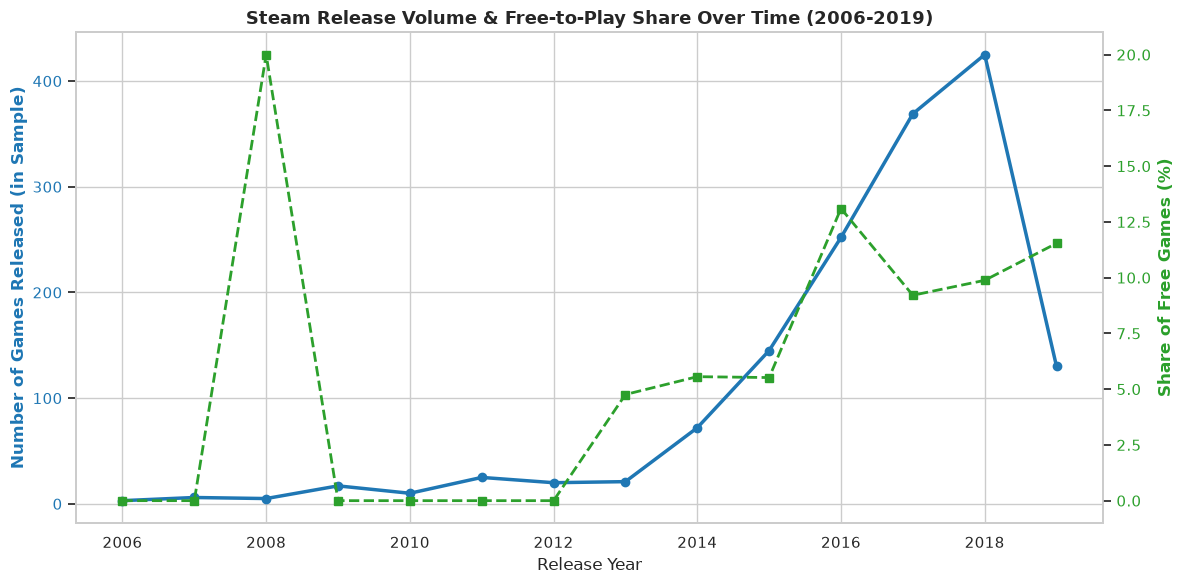

In [12]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color1 = "#1f77b4"
ax1.set_xlabel("Release Year")
ax1.set_ylabel("Number of Games Released (in Sample)", color=color1, fontweight="bold")
line1 = ax1.plot(yearly_df["release_year"], yearly_df["games_released"], color=color1, marker="o", linewidth=2.5, label="Releases per Year")
ax1.tick_params(axis="y", labelcolor=color1)

# Second y-axis for Free-to-Play % share
ax2 = ax1.twinx()
color2 = "#2ca02c"
ax2.set_ylabel("Share of Free Games (%)", color=color2, fontweight="bold")
line2 = ax2.plot(yearly_df["release_year"], yearly_df["pct_free"], color=color2, marker="s", linestyle="--", linewidth=2, label="% Free to Play")
ax2.tick_params(axis="y", labelcolor=color2)
ax2.grid(False) # Turn off overlapping grid

ax1.set_title("Steam Release Volume & Free-to-Play Share Over Time (2006-2019)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## 9. Correlation Matrix & Data Leakage Control
> **CRITICAL VIVA CONCEPT: DATA LEAKAGE**
>
> Review ratings (`positive_ratings`, `negative_ratings`, `review_score`) and playtime (`average_playtime`, `median_playtime`) are **post-launch outcomes**. They only exist *after* players have purchased and played the game.
>
> In our EDA, we analyze them for descriptive purposes, but **they are strictly quarantined from future ML predictive models** because unreleased games do not have reviews or playtimes.


Insight: Strongest Pearson correlation: positive_ratings <-> negative_ratings (r = 0.901). Skewed columns (price, required_age, achievements, owners_mid, positive_ratings, negative_ratings, review_score, average_playtime, median_playtime) also include Spearman rank correlations. Post-launch fields are marked and must be excluded from ML features.


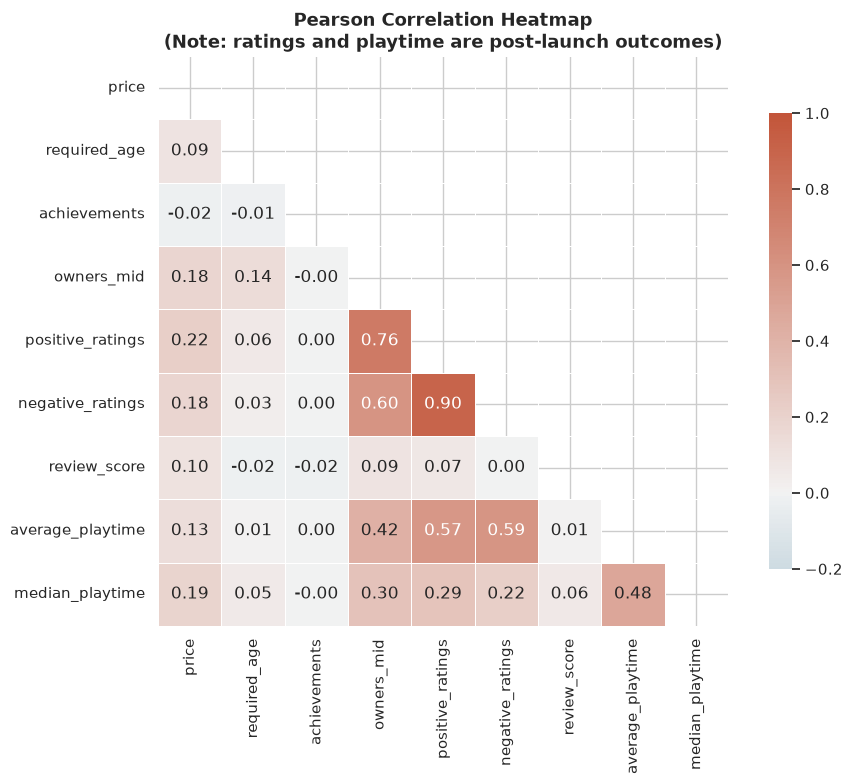

In [13]:
from eda.tables import correlation_table

corr_long_df, corr_insight = correlation_table(df_games)
print("Insight:", corr_insight)

# Build matrix for heatmap display
from eda.tables import NUMERIC_COLS
corr_matrix = df_games[NUMERIC_COLS].corr(method="pearson").round(2)

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap=cmap,
    vmax=1.0,
    vmin=-0.2,
    center=0,
    square=True,
    linewidths=0.5,
    annot=True,
    fmt=".2f",
    cbar_kws={"shrink": 0.8}
)
plt.title("Pearson Correlation Heatmap\n(Note: ratings and playtime are post-launch outcomes)",
          fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## 10. Popularity Tier Distribution & Imbalance
Our prediction target is `popularity_tier`:
- **Low**: $\le 20,000$ owners
- **Medium**: $20,000$ to $200,000$ owners
- **High**: $> 200,000$ owners


In [14]:
from eda.tables import tier_distribution

tier_df, tier_insight = tier_distribution(df_games)
print("Insight:", tier_insight)
tier_df


Insight: Class imbalance detected: Low 68.67% / Medium 22.67% / High 8.67% (Low:High ratio = 7.9:1). The High tier has only 130 games — stratified sampling or class weighting will be needed for ML.


,tier,count,percentage,imbalance_ratio_vs_High,is_imbalanced
0,Low,1030,68.67,7.9,True
1,Medium,340,22.67,2.6,True
2,High,130,8.67,1.0,True


### Visualization: Target Class Distribution


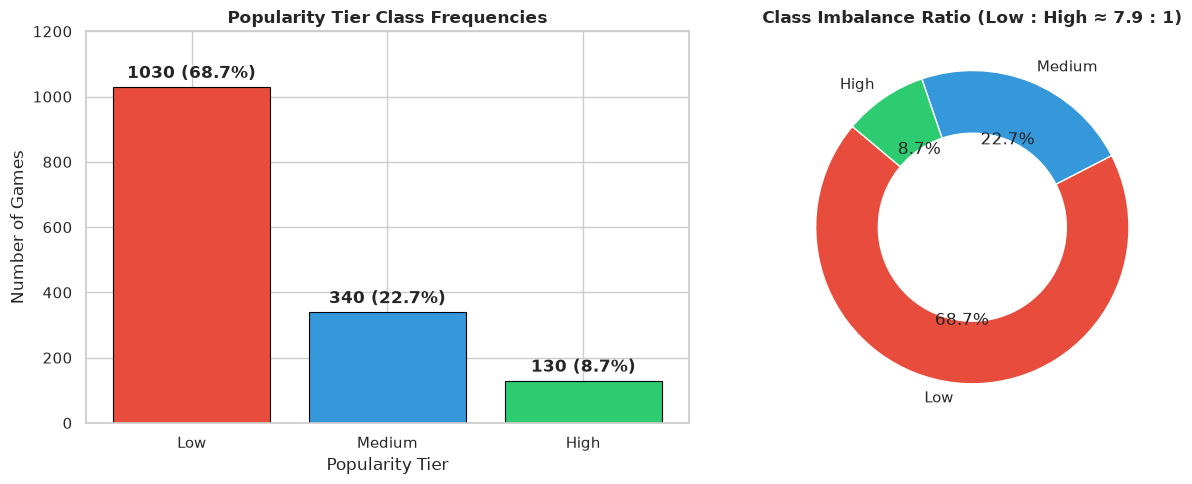

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart
colors = ["#e74c3c", "#3498db", "#2ecc71"]
bars = ax1.bar(tier_df["tier"], tier_df["count"], color=colors, edgecolor="black", linewidth=0.8)
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, yval + 15, f"{int(yval)} ({yval/1500*100:.1f}%)",
             ha="center", va="bottom", fontweight="bold")

ax1.set_title("Popularity Tier Class Frequencies", fontsize=12, fontweight="bold")
ax1.set_xlabel("Popularity Tier")
ax1.set_ylabel("Number of Games")
ax1.set_ylim(0, 1200)

# Donut / Pie chart
ax2.pie(
    tier_df["count"],
    labels=tier_df["tier"],
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor="w")
)
ax2.set_title("Class Imbalance Ratio (Low : High ≈ 7.9 : 1)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()


## 11. Conclusions & Machine Learning Roadmap (Viva Defense)

### Summary of Key Findings
1. **Target Imbalance**: Low tier accounts for **68.67%**, Medium for **22.67%**, and High for **8.67%**.
2. **Evaluation Metric**: Raw accuracy is misleading. **Macro-F1 score** must be the primary evaluation metric for Project 2 and Project 3.
3. **Pre-Launch vs. Post-Launch Features**: Post-launch outcomes (`positive_ratings`, `negative_ratings`, `review_score`, `playtime`) must be excluded from feature matrices to prevent data leakage.
4. **Transformations**: Due to heavy right-tail skewness, count features like achievements, price, and playtime require log or robust scaling.
5. **Multi-label Encoding**: Genres must be multi-hot encoded (binary vectors per genre).
6. **Modeling Strategy**: Linear correlations with popularity are weak ($r < 0.10$); tree ensembles (Random Forest, Gradient Boosting) and non-linear neural networks (MLP) are theoretically required to capture non-linear interactions across price bands, genres, and platform availability.
